# Results

In [3]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

# Baseline, RoBERTa, BERTWeet, and ModernBERT

In [17]:
files = glob.glob("../results/*_metrics.csv")
print(files)

['../results/baseline_metrics.csv', '../results/roberta_seed42_metrics.csv', '../results/bertweet_seed42_metrics.csv', '../results/modernbert_seed44_metrics.csv', '../results/roberta_seed44_metrics.csv', '../results/bertweet_seed44_metrics.csv', '../results/modernbert_seed42_metrics.csv', '../results/bertweet_seed43_metrics.csv', '../results/roberta_seed43_metrics.csv', '../results/modernbert_seed43_metrics.csv']


In [18]:
tables = []
for f in files:
    table = pd.read_csv(f)
    tables.append(table)

all_results = pd.concat(tables, ignore_index=True)

print(all_results)

         model       split  f1_sarcastic  f1_macro  precision    recall  seed
0     baseline  validation      0.336996  0.549887   0.319444  0.356589   NaN
1     baseline        test      0.280179  0.526656   0.199575  0.470000   NaN
2      roberta  validation      0.530612  0.672314   0.472727  0.604651  42.0
3      roberta        test      0.357542  0.568406   0.248062  0.640000  42.0
4     bertweet  validation      0.619529  0.733310   0.547619  0.713178  42.0
5     bertweet        test      0.450832  0.640563   0.323210  0.745000  42.0
6   modernbert  validation      0.452830  0.605245   0.380952  0.558140  44.0
7   modernbert        test      0.339853  0.533701   0.224919  0.695000  44.0
8      roberta  validation      0.465409  0.614320   0.391534  0.573643  44.0
9      roberta        test      0.324393  0.531061   0.217839  0.635000  44.0
10    bertweet  validation      0.619048  0.748299   0.634146  0.604651  44.0
11    bertweet        test      0.473779  0.672137   0.371105  0

In [19]:
test_results = all_results[all_results["split"] == "test"]
print(test_results)

         model split  f1_sarcastic  f1_macro  precision  recall  seed
1     baseline  test      0.280179  0.526656   0.199575   0.470   NaN
3      roberta  test      0.357542  0.568406   0.248062   0.640  42.0
5     bertweet  test      0.450832  0.640563   0.323210   0.745  42.0
7   modernbert  test      0.339853  0.533701   0.224919   0.695  44.0
9      roberta  test      0.324393  0.531061   0.217839   0.635  44.0
11    bertweet  test      0.473779  0.672137   0.371105   0.655  44.0
13  modernbert  test      0.254942  0.217494   0.147593   0.935  42.0
15    bertweet  test      0.475138  0.674432   0.376093   0.645  43.0
17     roberta  test      0.372712  0.600635   0.279302   0.560  43.0
19  modernbert  test      0.279938  0.532644   0.203160   0.450  43.0


In [20]:
val_results = all_results[all_results["split"] == "validation"]
print(val_results)

         model       split  f1_sarcastic  f1_macro  precision    recall  seed
0     baseline  validation      0.336996  0.549887   0.319444  0.356589   NaN
2      roberta  validation      0.530612  0.672314   0.472727  0.604651  42.0
4     bertweet  validation      0.619529  0.733310   0.547619  0.713178  42.0
6   modernbert  validation      0.452830  0.605245   0.380952  0.558140  44.0
8      roberta  validation      0.465409  0.614320   0.391534  0.573643  44.0
10    bertweet  validation      0.619048  0.748299   0.634146  0.604651  44.0
12  modernbert  validation      0.436823  0.394760   0.284706  0.937984  42.0
14    bertweet  validation      0.609375  0.740585   0.614173  0.604651  43.0
16     roberta  validation      0.456432  0.645826   0.491071  0.426357  43.0
18  modernbert  validation      0.404580  0.601515   0.398496  0.410853  43.0


In [28]:
metric_columns = ["f1_sarcastic", "f1_macro", "precision", "recall"]

test_summary = test_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])
print(test_summary.round(3))

val_summary = val_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])
print(val_summary.round(3))

           f1_sarcastic               f1_macro               precision         \
                  count   mean    std    count   mean    std     count   mean   
model                                                                           
baseline              1  0.280    NaN        1  0.527    NaN         1  0.200   
bertweet              3  0.467  0.014        3  0.662  0.019         3  0.357   
modernbert            3  0.292  0.044        3  0.428  0.182         3  0.192   
roberta               3  0.352  0.025        3  0.567  0.035         3  0.248   

                  recall                
              std  count   mean    std  
model                                   
baseline      NaN      1  0.470    NaN  
bertweet    0.029      3  0.682  0.055  
modernbert  0.040      3  0.693  0.243  
roberta     0.031      3  0.612  0.045  
           f1_sarcastic               f1_macro               precision         \
                  count   mean    std    count   mean    std    

To compare with the case where one guess that all tweets are sarcastic, the F1-score will be around 0.25.

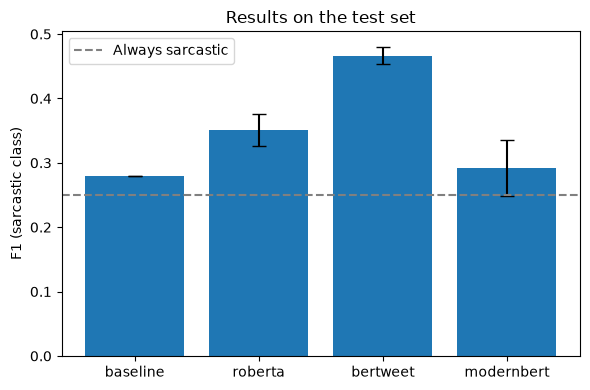

In [27]:
models = ["baseline", "roberta", "bertweet", "modernbert"]

means = test_summary.loc[models, ("f1_sarcastic", "mean")]
stds = test_summary.loc[models, ("f1_sarcastic", "std")].fillna(0)
# reference = test_summary.loc["always_sarcastic", ("f1_sarcastic", "mean")]
reference = 0.25

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, means, yerr=stds, capsize=5)
ax.axhline(reference, linestyle="--", color="gray", label="Always sarcastic")
ax.set_ylabel("F1 (sarcastic class)")
ax.set_title("Results on the test set")
ax.legend()
plt.tight_layout()
plt.savefig("../plots/f1_by_model.png", dpi=200)
plt.show()

## Collected results
| **Model** | **Validation F1** | **Test F1**|
|---|---|---|
| Always sarcastic | ~0.40 | ~0.25 |
| Baseline | 0.337 | 0.280 |
| RoBERTa | 0.484±0.04 | 0.352±0.025 |
| BERTweet | 0.616±0.006 | 0.467±0.014 |
| ModernBERT | 0.431±0.02 | 0.292±0.044 |

## Observations
1. **BERTweet is clearly the best one.** It has a F1-score of 0.467 on the testset. It also has the least variance between the seeds, with 0.014. 
2. **RoBERTa is better than the baseline.** This shows that a transformer that understand the connections in a sentence is better than a model that only looks at single words.
3. **ModernBERT performs the worst of the transformers.** It is only a bit better than the baseline. It also has the biggest variance between the seeds (0.044). With seed 42 it basicly learned nothing. 
4. For sarcasm in tweets it looks like a model trained on tweets is better than a newer model. The newest model actually performs the worst of the three that is trained on English text.
5. **All models performs worse on the test set than the validation set.** A possible explaination to this is that the test set has a lower share of sarcastic tweets than the training/validation set. All models has low precision and high recall on the test set, so they over predict sarcasm. 

# LLM: Qwen2.5-7B-Instruct
The LLM is tested in three ways (run on a Colab T4 GPU):
- **Zero-shot:** the model is only asked if the tweet is sarcastic (yes/no), no examples and no training.
- **10-shot:** 10 labelled examples from the training set (5 sarcastic, 5 not) are put in the prompt. Seeds 42, 43, 44 give three different sets of examples.
- **LoRA:** the LLM is fine-tuned as a classifier with LoRA, with the same data, class weights and model selection as the encoders. Seeds 42, 43, 44.

For zero-shot and 10-shot, the prediction is whichever of "yes"/"no" the model finds most likely. The tuned versions instead use the threshold that gives the best F1 on the validation set.

In [6]:
llm_models = ["qwen7b_0shot", "qwen7b_0shot_tuned", "qwen7b_10shot", "qwen7b_10shot_tuned", "qwen7b_lora"]
metric_columns = ["f1_sarcastic", "f1_macro", "precision", "recall"]

files = glob.glob("../results/*_metrics.csv")
print(files)

tables = []
for f in files:
    table = pd.read_csv(f)
    tables.append(table)

all_results = pd.concat(tables, ignore_index=True)
test_results = all_results[all_results["split"] == "test"]
val_results = all_results[all_results["split"] == "validation"]
test_summary = test_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])
val_summary = val_results.groupby("model")[metric_columns].agg(["count", "mean", "std"])

print("Test")
print(test_summary.loc[llm_models].round(3))
print()
print()
print("Validation")
print(val_summary.loc[llm_models].round(3))

['../results/baseline_metrics.csv', '../results/qwen7b_lora_seed42_metrics.csv', '../results/qwen7b_10shot_seed43_metrics.csv', '../results/qwen7b_lora_seed44_metrics.csv', '../results/qwen7b_10shot_seed42_metrics.csv', '../results/qwen7b_lora_seed43_metrics.csv', '../results/qwen7b_0shot_seed42_metrics.csv', '../results/qwen7b_10shot_seed44_metrics.csv']
Test
                    f1_sarcastic               f1_macro                \
                           count   mean    std    count   mean    std   
model                                                                   
qwen7b_0shot                   1  0.339    NaN        1  0.460    NaN   
qwen7b_0shot_tuned             1  0.424    NaN        1  0.612    NaN   
qwen7b_10shot                  3  0.472  0.054        3  0.654  0.069   
qwen7b_10shot_tuned            3  0.426  0.020        3  0.599  0.018   
qwen7b_lora                    3  0.485  0.059        3  0.665  0.049   

                    precision               recall  

In [ ]:
# test results per seed to see how much they vary
print(test_results[test_results["model"].isin(llm_models)].sort_values(["model", "seed"]).round(3))

                  model split  f1_sarcastic  f1_macro  precision  recall  seed
17         qwen7b_0shot  test         0.339     0.460      0.208   0.920  42.0
19   qwen7b_0shot_tuned  test         0.424     0.612      0.293   0.765  42.0
11        qwen7b_10shot  test         0.411     0.575      0.268   0.885  42.0
5         qwen7b_10shot  test         0.516     0.701      0.412   0.690  43.0
21        qwen7b_10shot  test         0.489     0.685      0.395   0.640  44.0
13  qwen7b_10shot_tuned  test         0.449     0.619      0.303   0.870  42.0
7   qwen7b_10shot_tuned  test         0.414     0.583      0.273   0.860  43.0
23  qwen7b_10shot_tuned  test         0.415     0.596      0.280   0.805  44.0
3           qwen7b_lora  test         0.552     0.720      0.430   0.770  42.0
15          qwen7b_lora  test         0.464     0.648      0.331   0.780  43.0
9           qwen7b_lora  test         0.440     0.628      0.310   0.760  44.0


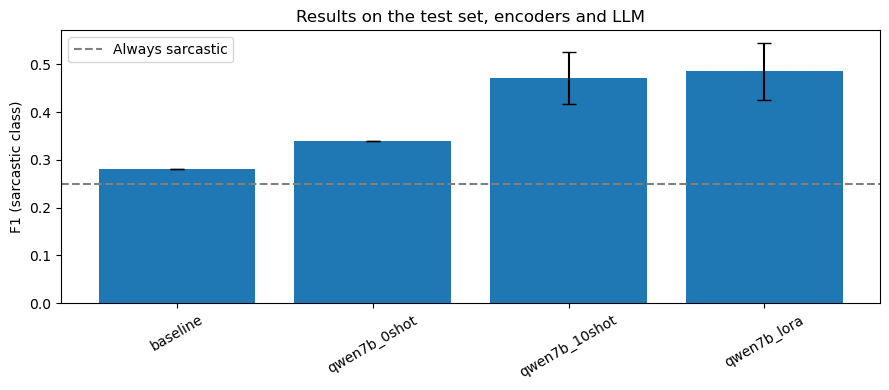

In [ ]:
all_models = [m for m in ["baseline", "roberta", "bertweet", "modernbert", "qwen7b_0shot", "qwen7b_10shot", "qwen7b_lora"] if m in test_summary.index]

means = test_summary.loc[all_models, ("f1_sarcastic", "mean")]
stds = test_summary.loc[all_models, ("f1_sarcastic", "std")].fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(all_models, means, yerr=stds, capsize=5)
ax.axhline(0.25, linestyle="--", color="gray", label="Always sarcastic")
ax.set_ylabel("F1 (sarcastic class)")
ax.set_title("Results on the test set, encoders and LLM")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig("../plots/f1_by_model_with_llm.png", dpi=200)
plt.show()

## Collected LLM results
| **Model** | **Validation F1** | **Test F1** | **Test precision** | **Test recall** |
|---|---|---|---|---|
| Qwen zero-shot | 0.492 | 0.339 | 0.208 | 0.920 |
| Qwen zero-shot, tuned threshold | 0.521 | 0.424 | 0.293 | 0.765 |
| Qwen 10-shot | 0.475±0.016 | 0.472±0.054 | 0.358±0.079 | 0.738±0.129 |
| Qwen 10-shot, tuned threshold | 0.505±0.003 | 0.426±0.020 | 0.285±0.016 | 0.845±0.035 |
| Qwen LoRA | 0.557±0.020 | 0.485±0.059 | 0.357±0.064 | 0.770±0.010 |

## Observations LLM
1. **Zero-shot Qwen says sarcastic to almost everything.** Recall is 0.92, but precision only 0.21, so on the test set it is just a little bit better than always guessing sarcastic (0.25).
2. **10 examples in the prompt is enough to reach the level of BERTweet**, without any training. Qwen 10-shot has a test F1 of 0.472, while BERTweet has 0.467. For Qwen 10-shot it does vary a lot between seeds (0.411–0.516) though, so which examples are chosen matters a lot.
3. **The tuned threshold makes 10-shot worse on the test set** (0.472 → 0.426), even though it is better on validation. The validation set has more sarcastic tweets than the test set, so a threshold chosen on validation makes the model predict sarcastic too often on the test set.
4. **LoRA fine-tuned Qwen has the highest mean test F1 (0.485), but it is not clearly better than BERTweet.** The difference (0.018) is much smaller than the std between seeds (0.059), and the seeds range from 0.440 to 0.552. On validation, BERTweet is actually better (0.616 vs 0.557).
5. **All have higher recall than precision on the test set,** so they also over predict sarcasm.

It is worth noting that the iSarcasmEval test set has been public since 2022, so the LLM might have seen it during pretraining (data contamination). This would make the LLM results look better than they really are.